# Project 1: SNLI classification

**One experiment:** compare BPE vocabulary sizes **1,000 / 2,000 / 3,000**, each
with indicators, unigram counts or pure bigram counts and logistic, MLP1 or MLP2.
Use the same five grouped CV splits for all **27 candidates**. Fit a fresh BPE
and bigram inventory on each fold's training text, shared by its nine systems.
Select the highest mean CV accuracy, then fit one fresh final pipeline on all
eligible training + validation data and evaluate that winner on test.

Vocabulary size is the **only tuned hyperparameter**. The bigram cap remains
2,000; all optimizer, regularization and training-length settings are fixed.
There is no validation-based early stopping. All custom code and tables are in
this notebook. Plots are exported as PNG/PDF to `figures/project1_vocab_cv/`.
There are no trial logs, checkpoints or local helper imports. Run All retrains.

No held-out fold text enters its fitted BPE, inventory or classifier. Different
folds may learn different token IDs; each fitted pipeline uses its own mapping
consistently. The final test is excluded from learned preprocessing and selection.
Earlier work already evaluated other models on test, which remains disclosed.
The best CV score is a selection score among 27 candidates, not an unbiased
nested-CV estimate of the complete selection procedure.


## 1. Configuration: tune vocabulary size only

The BPE candidates are 1,000, 2,000 and 3,000 tokens. Keep the bigram cap fixed
at 2,000 to avoid changing two hyperparameters together. Indicator/unigram pair
inputs have up to 2,000 / 4,000 / 6,000 columns; bigram inputs have up to 4,000.
Changing BPE size also changes segmentation, coverage and neural parameter count.
The tables therefore report dimensions, parameters and fit time as well as scores.
Both neural architectures train for three fixed epochs in CV and final refitting.


In [35]:
from array import array
from collections import Counter
from itertools import chain, combinations
from pathlib import Path
from time import perf_counter
import random
import warnings

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.stats import t
import torch
from torch import nn
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from datasets import DatasetDict, disable_progress_bars, load_dataset, load_from_disk
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import Metaspace
from tokenizers.trainers import BpeTrainer
from IPython.display import HTML, display

disable_progress_bars()
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "part1/project.ipynb").exists())
PART1 = ROOT / "part1"
FIGURES = PART1 / "figures/project1_vocab_cv"
LABELS = ["entailment", "neutral", "contradiction"]
REPRESENTATIONS = ["indicators", "unigram_counts", "bigram_counts"]
CLASSIFIERS = ["logistic", "mlp_one_hidden", "mlp_two_hidden"]

BASE = {
    "revision": "cdb5c3d5eed6ead6e5a341c8e56e669bb666725b",
    "vocab_sizes": [1000, 2000, 3000],
    "bpe_min_frequency": 2,
    "bigram_min_frequency": 2,
    "max_bigrams": 2000,
    "hidden_dims": {"mlp_one_hidden": [128], "mlp_two_hidden": [128, 64]},
    "dropout": 0.1,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "batch_size": 128,
    "epochs": 3,
    "logistic": {"solver": "saga", "C": 1.0, "max_iter": 1000, "tol": 0.0001},
    "cv_rows": 60000,
    "n_splits": 5,
    "cv_seeds": [0],
    "model_seed": 0,
    "sampling_seed": 0,
    "rope": 0.005,
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def save_figure(figure, name):
    FIGURES.mkdir(parents=True, exist_ok=True)
    for extension in ("png", "pdf"):
        figure.savefig(FIGURES / f"{name}.{extension}", dpi=180, bbox_inches="tight")


set_seed(BASE["model_seed"])
torch.set_num_threads(1)
display(pd.DataFrame({"setting": list(BASE), "value": [str(value) for value in BASE.values()]}))


,setting,value
0,revision,cdb5c3d5eed6ead6e5a341c8e56e669bb666725b
1,vocab_sizes,"[1000, 2000, 3000]"
2,bpe_min_frequency,2
3,bigram_min_frequency,2
4,max_bigrams,2000
5,hidden_dims,"{'mlp_one_hidden': [128], 'mlp_two_hidden': [1..."
6,dropout,0.1
7,learning_rate,0.001
8,weight_decay,0.0001
9,batch_size,128


## 2. Data and CV partitions

SNLI has three labels: entailment, neutral and contradiction. Remove unlabelled
or blank pairs, combine the official training and validation splits, and exclude
pairs whose exact premise appears in test. This gives **559,164 eligible
development pairs** with **154,028 distinct premises**. Only test-premise
membership is used for this exclusion.

**What is the current CV subset (`cv_data`)?** It is a fixed random sample from
that development pool. A premise group contains every pair with the same exact
premise text. `sample_groups` shuffles the groups using **sampling seed 0**, then
includes complete groups until reaching the **60,000-pair target** set by
`BASE["cv_rows"]`. Keeping the last group complete gives **60,002 pairs from
16,512 premise groups**. This subset was chosen to limit runtime.

The **same subset and five fold assignments** are reused for all 27 candidates.
Each fold trains on approximately **48,000 pairs** and validates on approximately
**12,000 pairs**, keeping premise groups disjoint. Each fold's BPE learns only
from its training pairs. The current CV scores and ROPE plots use these folds.

After selection, the final fresh tokenizer and classifier train on **all 559,164
development pairs**, including those outside the CV subset. Final evaluation
uses the separate **9,824-pair test set**.


In [36]:
def load_snli(config=BASE):
    directory = PART1 / "data/snli" / config["revision"] / "cleaned-v1"
    if directory.exists():
        return load_from_disk(str(directory))

    raw = load_dataset(
        "stanfordnlp/snli",
        revision=config["revision"],
        cache_dir=str(PART1 / "data/huggingface"),
    )
    cleaned = {}
    for split, rows in raw.items():
        rows = rows.map(
            lambda row, index: {"example_id": f"{split}:{index}"},
            with_indices=True,
        )
        cleaned[split] = rows.filter(
            lambda row: row["label"] in (0, 1, 2)
            and all(isinstance(row[field], str) and row[field].strip()
                    for field in ("premise", "hypothesis"))
        )
    return DatasetDict(cleaned)


def development_pool(data):
    frames = []
    for split in ("train", "validation"):
        frame = data[split].select_columns(
            ["premise", "hypothesis", "label", "example_id"]
        ).to_pandas()
        frame["source_split"] = split
        frames.append(frame)

    combined = pd.concat(frames, ignore_index=True)
    test_premises = set(data["test"]["premise"])
    development = combined.loc[~combined.premise.isin(test_premises)].copy()
    development["premise_group"] = development.premise
    development = development.reset_index(drop=True)

    assert development.example_id.is_unique
    assert set(development.premise).isdisjoint(test_premises)
    assert set(development.source_split) <= {"train", "validation"}
    return development


def sample_groups(frame, target_rows, seed):
    if not 1 <= target_rows <= len(frame):
        raise ValueError("The sample target must lie within the development pool.")

    sizes = frame.groupby("premise_group", sort=True).size()
    shuffled = sizes.iloc[np.random.default_rng(seed).permutation(len(sizes))]
    count = np.searchsorted(shuffled.cumsum(), target_rows) + 1
    selected = frame.premise_group.isin(shuffled.index[:count])
    return frame.loc[selected].reset_index(drop=True)


def make_assignments(frame, config=BASE):
    assignments = frame[["premise_group", "label"]].copy()
    for seed in config["cv_seeds"]:
        splitter = StratifiedGroupKFold(
            n_splits=config["n_splits"], shuffle=True, random_state=seed
        )
        for fold, (_, heldout) in enumerate(
            splitter.split(frame, frame.label, frame.premise_group)
        ):
            assignments.loc[heldout, f"fold_seed_{seed}"] = fold
        assignments[f"fold_seed_{seed}"] = assignments[f"fold_seed_{seed}"].astype(int)
    return assignments


data = load_snli()
assert all(data[split].features["label"].names == LABELS for split in data)
development = development_pool(data)
cv_data = sample_groups(development, BASE["cv_rows"], BASE["sampling_seed"])
assignments = make_assignments(cv_data)

display(pd.DataFrame({"split": list(data), "clean_rows": [len(data[split]) for split in data]}))
display(pd.DataFrame({
    "pool": ["Full development / BPE / final fit", "CV subset"],
    "rows": [len(development), len(cv_data)],
    "premise_groups": [development.premise_group.nunique(), cv_data.premise_group.nunique()],
}))
display(pd.crosstab(development.source_split, development.label).rename(columns=dict(enumerate(LABELS))))


,split,clean_rows
0,train,549367
1,validation,9842
2,test,9824


,pool,rows,premise_groups
0,Full development / BPE / final fit,559164,154028
1,CV subset,60002,16512


label,entailment,neutral,contradiction
source_split,,,
train,183402,182751,183172
validation,3328,3234,3277


### Sentence lengths and label balance

Compare the **559,164-pair development pool** with the **60,002-pair CV subset**.
Sentence length counts **whitespace-separated words before BPE**, separately for
premises and hypotheses. The distributions are normalized so pools of different
sizes can be compared; the table reports their means, medians, 95th percentiles
and maxima. The label plot shows the share of pairs in each inference class.

The CV sample closely matches the full pool in these two properties. Mean
premise/hypothesis lengths are **12.85 / 7.44 words** in the sample, compared
with **12.87 / 7.42 words** in full development. Each label accounts for roughly
**one third of the pairs** in both pools. Both figures are exported as **PNG
and PDF** to
`figures/project1_vocab_cv/`.


,pool,sentence,pairs,mean_words,median_words,p95_words,max_words
0,Full development,premise,559164,12.87,12.0,23.0,78
1,Full development,hypothesis,559164,7.42,7.0,13.0,56
2,CV subset,premise,60002,12.85,12.0,23.0,64
3,CV subset,hypothesis,60002,7.44,7.0,13.0,48


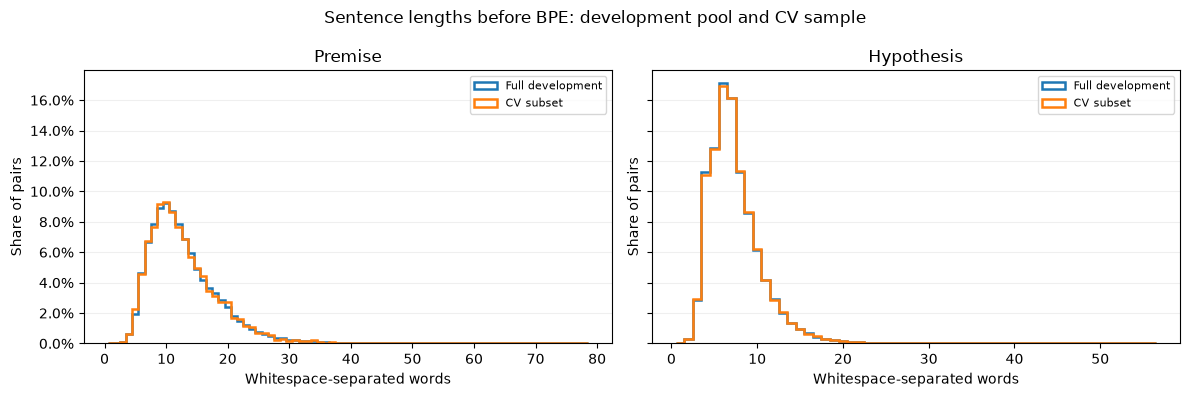

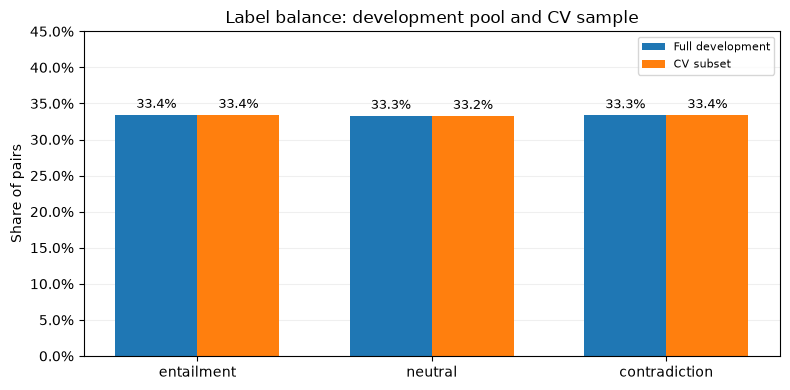

In [3]:
pools = {"Full development": development, "CV subset": cv_data}
sentence_lengths = {
    name: pd.DataFrame({
        role: frame[role].map(lambda text: len(text.split()))
        for role in ("premise", "hypothesis")
    })
    for name, frame in pools.items()
}
length_summary = pd.DataFrame([
    {"pool": name, "sentence": role, "pairs": len(values),
     "mean_words": values.mean(), "median_words": values.median(),
     "p95_words": values.quantile(0.95), "max_words": values.max()}
    for name, lengths in sentence_lengths.items()
    for role, values in lengths.items()
])
display(length_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, role in zip(axes, ("premise", "hypothesis")):
    maximum = max(lengths[role].max() for lengths in sentence_lengths.values())
    bins = np.arange(0.5, maximum + 1.5)
    for name, lengths in sentence_lengths.items():
        ax.hist(lengths[role], bins=bins, density=True, histtype="step",
                linewidth=1.8, label=name)
    ax.set(title=role.capitalize(), xlabel="Whitespace-separated words", ylabel="Share of pairs")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Sentence lengths before BPE: development pool and CV sample")
fig.tight_layout()
save_figure(fig, "dataset_sentence_lengths")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(LABELS))
for offset, (name, frame) in enumerate(pools.items()):
    shares = frame.label.value_counts(normalize=True).reindex(range(len(LABELS)), fill_value=0)
    bars = ax.bar(positions + (offset - 0.5) * 0.35, shares, width=0.35, label=name)
    ax.bar_label(bars, labels=[f"{value:.1%}" for value in shares], padding=3, fontsize=9)
ax.set(xticks=positions, xticklabels=LABELS, ylim=(0, 0.45), ylabel="Share of pairs",
       title="Label balance: development pool and CV sample")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "dataset_label_balance")
plt.show()


## 3. Fold-trained BPE and feature representations

For each vocabulary size in each fold, fit BPE on that fold's training premises
and hypotheses only. Encode validation text using that fixed mapping; no
validation text or labels enter preprocessing fitting. All nine systems in that
fold/size share the tokenizer and training-only bigram inventory.

The input remains `[premise features; hypothesis features]`: binary indicators,
raw unigram counts, or retained adjacent BPE-bigram counts. Sentence roles stay
separate, bigrams never cross boundaries, and pure bigrams have no unigram fallback.
Casing and punctuation are preserved and Metaspace handles word boundaries.
Different folds' token coordinates need not match: models are fitted and evaluated
inside their own feature spaces, while the resulting scores can be compared.


In [37]:
def fit_tokenizer(training_text, vocab_size, config=BASE):
    tokenizer = Tokenizer(BPE(unk_token="[UNK]"))
    tokenizer.pre_tokenizer = Metaspace(
        replacement="▁", prepend_scheme="always", split=True
    )
    trainer = BpeTrainer(
        vocab_size=vocab_size,
        min_frequency=config["bpe_min_frequency"],
        special_tokens=["[UNK]"],
        show_progress=False,
    )
    texts = chain.from_iterable(zip(training_text.premise, training_text.hypothesis))
    tokenizer.train_from_iterator(texts, trainer=trainer, length=2 * len(training_text))
    return tokenizer


def encode_pairs(tokenizer, frame, batch_size=2048):
    roles = []
    for name in ("premise", "hypothesis"):
        ids, offsets = array("i"), array("q", [0])
        texts = frame[name].tolist()
        for start in range(0, len(texts), batch_size):
            encodings = tokenizer.encode_batch(texts[start:start + batch_size])
            for encoding in encodings:
                ids.extend(encoding.ids)
                offsets.append(len(ids))
        roles.append((np.asarray(ids, dtype=np.int32), np.asarray(offsets, dtype=np.int64)))
    return roles


def learn_bigrams(tokens, config=BASE):
    counts = Counter()
    for ids, offsets in tokens:
        for start, end in zip(offsets[:-1], offsets[1:]):
            sentence = ids[start:end].tolist()
            counts.update(zip(sentence, sentence[1:]))
    ranked = sorted(counts.items(), key=lambda item: (-item[1], item[0]))
    retained = [pair for pair, count in ranked if count >= config["bigram_min_frequency"]]
    return retained[:config["max_bigrams"]]


class PairEncoder:
    def __init__(self, tokenizer, bigrams):
        self.tokenizer = tokenizer
        self.vocab_size = tokenizer.get_vocab_size()
        self.bigrams = bigrams


In [38]:
def feature_matrix(encoder, tokens, representation):
    """Construct sparse premise/hypothesis blocks without cross-sentence bigrams."""
    width = encoder.vocab_size
    inventory = np.array([a * width + b for a, b in encoder.bigrams], dtype=np.int64)
    permutation = np.argsort(inventory)
    sorted_pairs = inventory[permutation]
    blocks = []
    for ids, offsets in tokens:
        n_rows = len(offsets) - 1
        if representation in ("indicators", "unigram_counts"):
            rows = np.repeat(np.arange(n_rows), np.diff(offsets))
            block = sparse.csr_matrix((np.ones(len(ids), np.float32), (rows, ids)), shape=(n_rows, width))
            if representation == "indicators":
                block.data.fill(1)
        elif representation == "bigram_counts":
            valid = np.ones(max(0, len(ids) - 1), dtype=bool)
            boundaries = offsets[1:-1] - 1
            valid[boundaries[(boundaries >= 0) & (boundaries < len(valid))]] = False
            positions = np.flatnonzero(valid)
            pairs = ids[positions].astype(np.int64) * width + ids[positions + 1]
            locations = np.searchsorted(sorted_pairs, pairs)
            keep = locations < len(sorted_pairs)
            if len(sorted_pairs):
                keep[keep] &= sorted_pairs[locations[keep]] == pairs[keep]
            rows = np.searchsorted(offsets[1:], positions[keep], side="right")
            block = sparse.csr_matrix((np.ones(len(rows), np.float32), (rows, permutation[locations[keep]])),
                                      shape=(n_rows, len(inventory)))
        else:
            raise ValueError(f"Unknown representation: {representation}")
        blocks.append(block)
    return sparse.hstack(blocks, format="csr", dtype=np.float32)


## 4. Classifiers and fixed training loop

Logistic regression uses a multinomial softmax with L2 regularization. The MLPs
use a sparse first layer, ReLU, dropout and one or two hidden layers. Their output
is log-softmax; `NLLLoss` matches that output. AdamW applies decoupled weight decay.
Each neural fit takes exactly three epochs, without accessing held-out labels.


In [39]:
def score(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int64)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    assert probabilities.shape == (len(labels), 3) and len(labels) > 0
    assert np.isfinite(probabilities).all() and (probabilities >= 0).all()
    assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)
    predictions = probabilities.argmax(axis=1)
    gold_probabilities = probabilities[np.arange(len(labels)), labels]
    return {
        "accuracy": accuracy_score(labels, predictions),
        "nll": -np.log(np.clip(gold_probabilities, np.finfo(float).eps, 1)).mean(),
        "macro_f1": f1_score(
            labels, predictions, labels=[0, 1, 2], average="macro", zero_division=0
        ),
    }


def sparse_tensor(matrix):
    coo = matrix.tocoo()
    indices = torch.from_numpy(np.vstack((coo.row, coo.col)).astype(np.int64))
    values = torch.from_numpy(np.asarray(coo.data, dtype=np.float32))
    return torch.sparse_coo_tensor(indices, values, coo.shape, check_invariants=True).coalesce()


class PairMLP(nn.Module):
    def __init__(self, input_dim, hidden_dims, dropout):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(input_dim, hidden_dims[0]))
        self.bias = nn.Parameter(torch.zeros(hidden_dims[0]))
        nn.init.xavier_uniform_(self.weight)
        layers = [nn.ReLU(), nn.Dropout(dropout)]
        for before, after in zip(hidden_dims, hidden_dims[1:]):
            layers.extend([nn.Linear(before, after), nn.ReLU(), nn.Dropout(dropout)])
        layers.extend([nn.Linear(hidden_dims[-1], 3), nn.LogSoftmax(dim=-1)])
        self.output = nn.Sequential(*layers)

    def forward(self, features):
        hidden = torch.sparse.mm(features, self.weight) + self.bias
        return self.output(hidden)


def predict_proba(fitted, features, batch_size=1024):
    model = fitted["model"]
    if fitted["classifier"] == "logistic":
        assert np.array_equal(model.classes_, [0, 1, 2])
        return model.predict_proba(features)

    model.eval()
    probabilities = []
    with torch.no_grad():
        for start in range(0, features.shape[0], batch_size):
            batch = sparse_tensor(features[start:start + batch_size])
            probabilities.append(model(batch).exp().numpy())
    return np.concatenate(probabilities)


In [40]:
def fit_model(features, labels, classifier, config=BASE):
    labels = np.asarray(labels, dtype=np.int64)
    assert features.shape[0] == len(labels) and set(labels) == {0, 1, 2}
    set_seed(config["model_seed"])

    if classifier == "logistic":
        model = LogisticRegression(
            **config["logistic"], l1_ratio=0.0, random_state=config["model_seed"]
        )
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            model.fit(features, labels)
        converged = not any(issubclass(item.category, ConvergenceWarning) for item in caught)
        return {"classifier": classifier, "model": model, "history": [], "converged": converged}

    model = PairMLP(
        features.shape[1], config["hidden_dims"][classifier], config["dropout"]
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["learning_rate"], weight_decay=config["weight_decay"]
    )
    criterion = nn.NLLLoss()
    random_order = np.random.default_rng(config["model_seed"])
    history = []

    for epoch in range(config["epochs"]):
        model.train()
        order = random_order.permutation(len(labels))
        total_loss, correct = 0.0, 0

        for start in range(0, len(labels), config["batch_size"]):
            indices = order[start:start + config["batch_size"]]
            batch = sparse_tensor(features[indices])
            target = torch.as_tensor(labels[indices], dtype=torch.long)

            optimizer.zero_grad(set_to_none=True)
            log_probabilities = model(batch)
            loss = criterion(log_probabilities, target)
            assert torch.isfinite(loss)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(indices)
            correct += (log_probabilities.argmax(dim=1) == target).sum().item()

        history.append({
            "epoch": epoch + 1,
            "training_nll_online": total_loss / len(labels),
            "training_accuracy_online": correct / len(labels),
        })

    model.eval()
    return {"classifier": classifier, "model": model, "history": history, "converged": True}


## 5. Paired CV and vocabulary-size selection

Use the same 60,002-row whole-premise-group subset and five folds for every
candidate. Only vocabulary size varies as a tuned hyperparameter; all nine
representation/architecture combinations are evaluated at every size.

Select the highest unrounded **mean CV accuracy** among all 27 combinations,
then lower NLL for an exact tie, then smaller vocabulary and lexical system order
for any remaining exact ties. Do not choose a checkpoint or alter settings using
held-out scores. The selected maximum is subject to selection optimism; there is
no separate nested outer CV in this budgeted experiment.

Report the best system per size, all 27 results, and a matrix comparing sizes
within each fixed representation/classifier. Do not interpret changes between
different per-size winning architectures as vocabulary-only effects. Fold SD is
descriptive variation among dependent folds, not an independent-sample error bar.


In [41]:
def run_cv(data, assignments, config=BASE):
    results = []
    predictions = []

    for seed in config["cv_seeds"]:
        for fold in range(config["n_splits"]):
            heldout = assignments[f"fold_seed_{seed}"].eq(fold)
            training = data.loc[~heldout]
            validation = data.loc[heldout]
            assert set(training.premise_group).isdisjoint(validation.premise_group)

            for vocab_size in config["vocab_sizes"]:
                started = perf_counter()

                # Fit preprocessing only on this fold's training text.
                tokenizer = fit_tokenizer(
                    training[["premise", "hypothesis"]], vocab_size, config
                )
                tokenizer_snapshot = tokenizer.to_str()
                train_tokens = encode_pairs(tokenizer, training)
                val_tokens = encode_pairs(tokenizer, validation)
                encoder = PairEncoder(tokenizer, learn_bigrams(train_tokens, config))
                val_tokens_per_pair = sum(len(ids) for ids, _ in val_tokens) / len(validation)

                for representation in REPRESENTATIONS:
                    train_features = feature_matrix(encoder, train_tokens, representation)
                    val_features = feature_matrix(encoder, val_tokens, representation)

                    for classifier in CLASSIFIERS:
                        fit_started = perf_counter()
                        fitted = fit_model(train_features, training.label, classifier, config)
                        fit_seconds = perf_counter() - fit_started
                        probabilities = predict_proba(fitted, val_features)
                        model = fitted["model"]
                        parameters = (model.coef_.size + model.intercept_.size
                                      if classifier == "logistic"
                                      else sum(parameter.numel() for parameter in model.parameters()))

                        results.append({
                            "seed": seed, "fold": fold, "vocab_size": vocab_size,
                            "representation": representation, "classifier": classifier,
                            "actual_vocab": encoder.vocab_size,
                            "retained_bigrams": len(encoder.bigrams),
                            "input_dimensions": train_features.shape[1],
                            "parameters": parameters, "fit_seconds": fit_seconds,
                            "val_tokens_per_pair": val_tokens_per_pair,
                            "converged": fitted["converged"],
                            **score(validation.label, probabilities),
                        })

                        # Keep one OOF repetition for error analysis, in memory only.
                        if seed == config["cv_seeds"][0]:
                            prediction = pd.DataFrame(probabilities, columns=["p0", "p1", "p2"])
                            prediction["row"] = validation.index.to_numpy()
                            prediction["vocab_size"] = vocab_size
                            prediction["representation"] = representation
                            prediction["classifier"] = classifier
                            predictions.append(prediction)

                assert tokenizer.to_str() == tokenizer_snapshot
                print(f"Seed {seed}, fold {fold + 1}/{config['n_splits']}, "
                      f"BPE {vocab_size}: nine fits complete "
                      f"({perf_counter() - started:.1f} seconds)", flush=True)

    return pd.DataFrame(results), pd.concat(predictions, ignore_index=True)


def summarise_cv(results):
    return results.groupby(["vocab_size", "representation", "classifier"], as_index=False).agg(
        cv_accuracy=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
        cv_nll=("nll", "mean"), cv_macro_f1=("macro_f1", "mean"),
        folds=("fold", "size"), converged=("converged", "all"),
        input_dimensions=("input_dimensions", "max"), parameters=("parameters", "max"),
        mean_fit_seconds=("fit_seconds", "mean"),
    ).sort_values(
        ["cv_accuracy", "cv_nll", "vocab_size", "representation", "classifier"],
        ascending=[False, True, True, True, True],
    ).reset_index(drop=True)


In [42]:
cv_started = perf_counter()
cv_results, oof_predictions = run_cv(cv_data, assignments)
cv_seconds = perf_counter() - cv_started
expected_fits = len(BASE["cv_seeds"]) * BASE["n_splits"] * len(BASE["vocab_sizes"]) * 9
assert len(cv_results) == expected_fits
assert not cv_results.duplicated(["seed", "fold", "vocab_size", "representation", "classifier"]).any()

cv_summary = summarise_cv(cv_results)
winner = cv_summary.iloc[0]
selected_vocab = int(winner.vocab_size)
selected_results = cv_results.loc[cv_results.vocab_size.eq(selected_vocab)]
selected_summary = cv_summary.loc[cv_summary.vocab_size.eq(selected_vocab)]
best_per_vocab = cv_summary.drop_duplicates("vocab_size").sort_values("vocab_size")
formats = {"cv_accuracy": "{:.2%}", "accuracy_std": "{:.2%}",
           "cv_nll": "{:.4f}", "cv_macro_f1": "{:.4f}", "mean_fit_seconds": "{:.2f}"}

print("Best CV system at each vocabulary size:")
display(best_per_vocab.style.format(formats))
print("All 27 combinations (CV selection scores):")
display(cv_summary.sort_values(["vocab_size", "cv_accuracy"], ascending=[True, False]).style.format(formats))
print("Controlled comparison: mean CV accuracy for each fixed system:")
accuracy_by_vocab = cv_summary.pivot(
    index=["representation", "classifier"], columns="vocab_size", values="cv_accuracy"
)
display(accuracy_by_vocab.style.format("{:.2%}"))
print("Change from vocabulary 2000, in percentage points:")
display(accuracy_by_vocab.sub(accuracy_by_vocab[2000], axis=0).mul(100).style.format("{:+.2f}"))

tokenizer_summary = cv_results.drop_duplicates(["seed", "fold", "vocab_size"]).groupby("vocab_size").agg(
    actual_vocab=("actual_vocab", "min"), retained_bigrams=("retained_bigrams", "min"),
    mean_validation_tokens_per_pair=("val_tokens_per_pair", "mean"),
)
display(tokenizer_summary.round(2))
display(HTML("<details><summary>Complete per-fold measurements</summary>"
             + cv_results.to_html(index=False, float_format=lambda value: f"{value:.10g}")
             + "</details>"))
print(f"Selected BPE {selected_vocab}: {winner.representation} + {winner.classifier}; "
      f"mean CV accuracy {winner.cv_accuracy:.2%}")
print(f"CV elapsed: {cv_seconds / 60:.2f} minutes; {expected_fits} classifier fits")


Seed 0, fold 1/5, BPE 1000: nine fits complete (41.5 seconds)
Seed 0, fold 1/5, BPE 2000: nine fits complete (39.2 seconds)
Seed 0, fold 1/5, BPE 3000: nine fits complete (44.8 seconds)
Seed 0, fold 2/5, BPE 1000: nine fits complete (40.2 seconds)
Seed 0, fold 2/5, BPE 2000: nine fits complete (38.7 seconds)
Seed 0, fold 2/5, BPE 3000: nine fits complete (45.2 seconds)
Seed 0, fold 3/5, BPE 1000: nine fits complete (41.3 seconds)
Seed 0, fold 3/5, BPE 2000: nine fits complete (36.9 seconds)
Seed 0, fold 3/5, BPE 3000: nine fits complete (42.5 seconds)
Seed 0, fold 4/5, BPE 1000: nine fits complete (36.2 seconds)
Seed 0, fold 4/5, BPE 2000: nine fits complete (37.0 seconds)
Seed 0, fold 4/5, BPE 3000: nine fits complete (42.8 seconds)
Seed 0, fold 5/5, BPE 1000: nine fits complete (39.0 seconds)
Seed 0, fold 5/5, BPE 2000: nine fits complete (37.2 seconds)
Seed 0, fold 5/5, BPE 3000: nine fits complete (46.0 seconds)
Best CV system at each vocabulary size:


,vocab_size,representation,classifier,cv_accuracy,accuracy_std,cv_nll,cv_macro_f1,folds,converged,input_dimensions,parameters,mean_fit_seconds
5,1000,unigram_counts,mlp_two_hidden,62.27%,0.70%,0.8415,0.6207,5,True,2000,264579,2.42
0,2000,indicators,mlp_two_hidden,62.69%,0.65%,0.8400,0.6253,5,True,4000,520579,3.88
1,3000,indicators,mlp_two_hidden,62.55%,0.76%,0.8469,0.6237,5,True,6000,776579,5.76


All 27 combinations (CV selection scores):


,vocab_size,representation,classifier,cv_accuracy,accuracy_std,cv_nll,cv_macro_f1,folds,converged,input_dimensions,parameters,mean_fit_seconds
5,1000,unigram_counts,mlp_two_hidden,62.27%,0.70%,0.8415,0.6207,5,True,2000,264579,2.42
6,1000,indicators,mlp_two_hidden,62.25%,0.76%,0.8395,0.6209,5,True,2000,264579,2.54
10,1000,unigram_counts,mlp_one_hidden,61.44%,0.58%,0.8520,0.6131,5,True,2000,256515,2.01
11,1000,indicators,mlp_one_hidden,61.32%,0.59%,0.8517,0.6118,5,True,2000,256515,2.11
16,1000,indicators,logistic,59.77%,0.71%,0.8952,0.5968,5,True,2000,6003,6.16
17,1000,unigram_counts,logistic,59.74%,0.66%,0.8970,0.5964,5,True,2000,6003,12.94
18,1000,bigram_counts,mlp_one_hidden,55.82%,0.42%,0.9253,0.5572,5,True,4000,512515,3.33
19,1000,bigram_counts,mlp_two_hidden,55.80%,0.54%,0.9277,0.5554,5,True,4000,520579,3.66
20,1000,bigram_counts,logistic,54.82%,0.33%,0.9621,0.5474,5,True,4000,12003,2.69
0,2000,indicators,mlp_two_hidden,62.69%,0.65%,0.8400,0.6253,5,True,4000,520579,3.88


Controlled comparison: mean CV accuracy for each fixed system:


Change from vocabulary 2000, in percentage points:


,actual_vocab,retained_bigrams,mean_validation_tokens_per_pair
vocab_size,,,
1000,1000,2000,31.00
2000,2000,2000,26.57
3000,3000,2000,24.77


seed,fold,vocab_size,representation,classifier,actual_vocab,retained_bigrams,input_dimensions,parameters,fit_seconds,val_tokens_per_pair,converged,accuracy,nll,macro_f1
0,0,1000,indicators,logistic,1000,2000,2000,6003,6.491136466,30.74847955,True,0.6046821628,0.8916483097,0.6035377757
0,0,1000,indicators,mlp_one_hidden,1000,2000,2000,256515,2.368980369,30.74847955,True,0.6143464134,0.8500554352,0.6131631092
0,0,1000,indicators,mlp_two_hidden,1000,2000,2000,264579,3.024902267,30.74847955,True,0.6294259768,0.8358769859,0.6281776697
0,0,1000,unigram_counts,logistic,1000,2000,2000,6003,13.5071402,30.74847955,True,0.6032658502,0.8941978667,0.6020253074
0,0,1000,unigram_counts,mlp_one_hidden,1000,2000,2000,256515,2.03948076,30.74847955,True,0.6179288511,0.8504099767,0.6168758414
0,0,1000,unigram_counts,mlp_two_hidden,1000,2000,2000,264579,2.452861468,30.74847955,True,0.6298425394,0.8378472644,0.628118197
0,0,1000,bigram_counts,logistic,1000,2000,4000,12003,2.645862052,30.74847955,True,0.5501957844,0.9609612149,0.5493519498
0,0,1000,bigram_counts,mlp_one_hidden,1000,2000,4000,512515,3.31876684,30.74847955,True,0.5599433475,0.9251397243,0.5591759107
0,0,1000,bigram_counts,mlp_two_hidden,1000,2000,4000,520579,3.774127232,30.74847955,True,0.5601099725,0.9279411903,0.5577894637
0,0,2000,indicators,logistic,2000,2000,4000,12003,5.107491102,26.26360077,True,0.608014663,0.8905773297,0.6071138462


Selected BPE 2000: indicators + mlp_two_hidden; mean CV accuracy 62.69%
CV elapsed: 10.14 minutes; 135 classifier fits


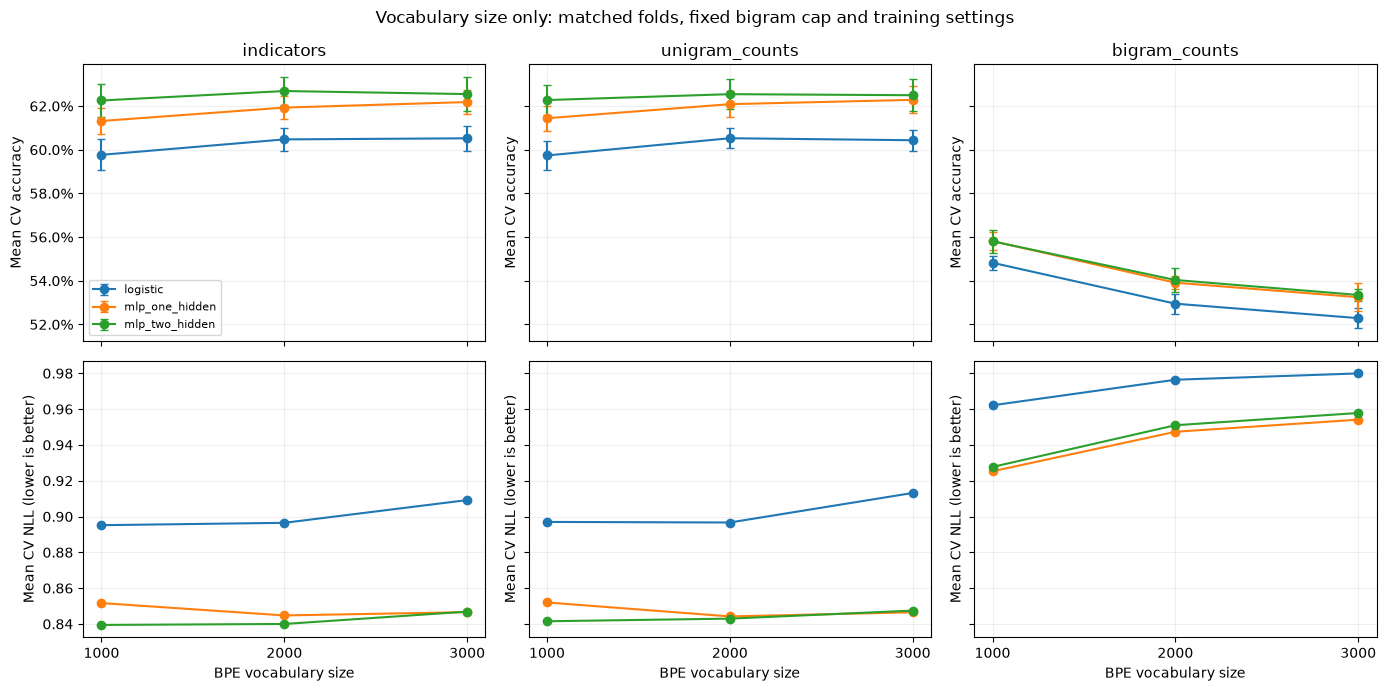

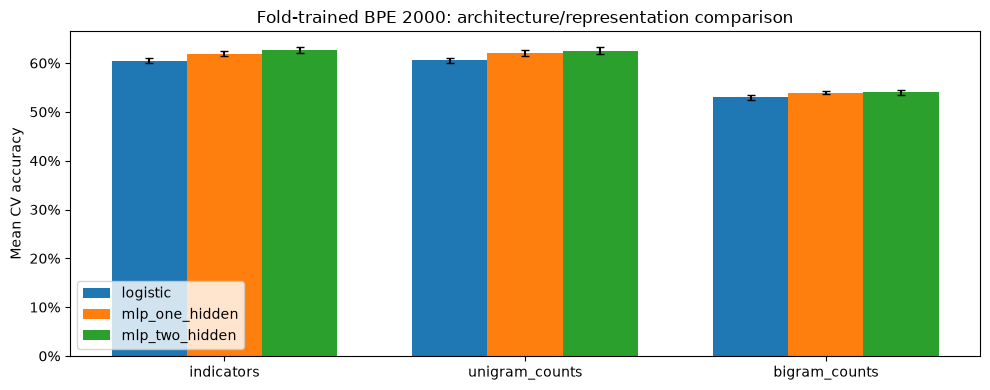

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey="row")
for column, representation in enumerate(REPRESENTATIONS):
    for classifier in CLASSIFIERS:
        rows = cv_summary.loc[
            cv_summary.representation.eq(representation) & cv_summary.classifier.eq(classifier)
        ].sort_values("vocab_size")
        axes[0, column].errorbar(rows.vocab_size, rows.cv_accuracy, yerr=rows.accuracy_std,
                                 marker="o", capsize=3, label=classifier)
        axes[1, column].plot(rows.vocab_size, rows.cv_nll, marker="o", label=classifier)
    axes[0, column].set(title=representation, ylabel="Mean CV accuracy")
    axes[0, column].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1, column].set(xlabel="BPE vocabulary size", ylabel="Mean CV NLL (lower is better)",
                        xticks=BASE["vocab_sizes"])
    for ax in axes[:, column]:
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Vocabulary size only: matched folds, fixed bigram cap and training settings")
fig.tight_layout()
save_figure(fig, "vocabulary_effect")
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
positions = np.arange(len(REPRESENTATIONS))
for offset, classifier in enumerate(CLASSIFIERS):
    rows = selected_summary.loc[selected_summary.classifier.eq(classifier)].set_index("representation")
    rows = rows.loc[REPRESENTATIONS]
    ax.bar(positions + (offset - 1) * 0.25, rows.cv_accuracy, width=0.25,
           yerr=rows.accuracy_std, capsize=3, label=classifier)
ax.set(xticks=positions, xticklabels=REPRESENTATIONS, ylabel="Mean CV accuracy",
       title=f"Fold-trained BPE {selected_vocab}: architecture/representation comparison")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
fig.tight_layout()
save_figure(fig, "cv_accuracy")
plt.show()


## 6. Bayesian comparisons and ROPE sensitivity

Compare matched fold accuracies using the tutorial's correlated-t model. The
posterior for **B − A** uses sample variance times
`1 / number_of_scores + 1 / (number_of_folds - 1)` to approximate dependence
from overlapping training folds. There are five paired scores per comparison.

The comparisons use the same five held-out CV accuracy scores:

- **Models/representations:** BPE vocabulary fixed at **2,000**; compare logistic
  regression, MLP1 (128), and MLP2 (128 → 64) with indicators, unigram counts,
  or pure bigram counts, changing one factor at a time.
- **Vocabulary sizes:** keep **indicators + MLP2** fixed; compare **1,000 vs 2,000**,
  **1,000 vs 3,000**, and **2,000 vs 3,000**.

These are descriptive post-selection comparisons using the same CV data, not
independent confirmation of the selected winner or global ranking probabilities.

The primary ROPE is ±0.005 accuracy (±0.5 percentage points), a project judgement
about a practically useful difference. Also show ±0.25 and ±1 pp sensitivity.
These tables describe uncertainty and do not override the fixed selection rule.


In [44]:
def correlated_posterior(a, b, n_splits=5, rope=0.005):
    difference = np.asarray(b, dtype=float) - np.asarray(a, dtype=float)
    count = len(difference)
    assert count >= 4 and count % n_splits == 0
    mean = difference.mean()
    scale = np.sqrt(difference.var(ddof=1) * (1 / count + 1 / (n_splits - 1)))

    if scale == 0:
        left, right = float(mean < -rope), float(mean > rope)
        low, high = mean, mean
        equivalent = 1 - left - right
    else:
        posterior = t(df=count - 1, loc=mean, scale=scale)
        left, right = posterior.cdf(-rope), posterior.sf(rope)
        equivalent = posterior.cdf(rope) - posterior.cdf(-rope)
        low, high = posterior.interval(0.95)

    return {
        "difference_B_minus_A": mean,
        "ci_low": low,
        "ci_high": high,
        "student_scale": scale,
        "degrees_of_freedom": count - 1,
        "P_A_better": left,
        "P_equivalent": equivalent,
        "P_B_better": right,
    }


def bayesian_comparisons(results, rope, config=BASE):
    paired = results.pivot(
        index=["seed", "fold"], columns=["representation", "classifier"], values="accuracy"
    ).sort_index()
    assert not paired.isna().any().any()
    rows = []
    systems = list(paired.columns)
    for a, b in combinations(systems, 2):
        if (a[0] == b[0]) == (a[1] == b[1]):
            continue  # Compare one changed factor at a time.
        posterior = correlated_posterior(paired[a], paired[b], config["n_splits"], rope)
        rows.append({"A": " / ".join(a), "B": " / ".join(b), **posterior})
    return pd.DataFrame(rows)



def vocabulary_comparisons(results, representation, classifier, rope, config=BASE):
    scores = results.loc[
        results.representation.eq(representation) & results.classifier.eq(classifier)
    ].pivot(index=["seed", "fold"], columns="vocab_size", values="accuracy").sort_index()
    assert not scores.isna().any().any()
    rows = []
    for a, b in combinations(sorted(scores.columns), 2):
        posterior = correlated_posterior(scores[a], scores[b], config["n_splits"], rope)
        rows.append({"A": f"BPE {a}", "B": f"BPE {b}", **posterior})
    return pd.DataFrame(rows)


posteriors = bayesian_comparisons(selected_results, BASE["rope"])
vocab_posteriors = vocabulary_comparisons(
    cv_results, winner.representation, winner.classifier, BASE["rope"]
)
posterior_formats = {
    "difference_B_minus_A": lambda value: f"{100 * value:+.2f} pp",
    "ci_low": lambda value: f"{100 * value:+.2f} pp",
    "ci_high": lambda value: f"{100 * value:+.2f} pp",
    "P_A_better": "{:.2%}", "P_equivalent": "{:.2%}", "P_B_better": "{:.2%}",
}
print(f"Architecture/representation comparisons at BPE {selected_vocab}:")
display(posteriors.drop(columns=["student_scale", "degrees_of_freedom"]).style.format(posterior_formats))
print(f"Vocabulary comparisons for {winner.representation} / {winner.classifier}:")
display(vocab_posteriors.drop(columns=["student_scale", "degrees_of_freedom"]).style.format(posterior_formats))

sensitivity_rows = []
for width in [0.0025, 0.005, 0.01]:
    comparisons = pd.concat([
        bayesian_comparisons(selected_results, width),
        vocabulary_comparisons(cv_results, winner.representation, winner.classifier, width),
    ], ignore_index=True)
    comparisons["ROPE half-width (pp)"] = width * 100
    sensitivity_rows.append(comparisons)
sensitivity = pd.concat(sensitivity_rows, ignore_index=True)
display(sensitivity.pivot(
    index=["A", "B"], columns="ROPE half-width (pp)", values="P_equivalent"
).style.format("{:.2%}"))


Architecture/representation comparisons at BPE 2000:


,A,B,difference_B_minus_A,ci_low,ci_high,P_A_better,P_equivalent,P_B_better
0,indicators / logistic,indicators / mlp_one_hidden,+1.46 pp,+1.26 pp,+1.65 pp,0.00%,0.01%,99.99%
1,indicators / logistic,indicators / mlp_two_hidden,+2.21 pp,+1.70 pp,+2.73 pp,0.01%,0.03%,99.96%
2,indicators / logistic,unigram_counts / logistic,+0.05 pp,-0.13 pp,+0.23 pp,0.05%,99.83%,0.12%
3,indicators / logistic,bigram_counts / logistic,-7.52 pp,-8.94 pp,-6.11 pp,99.99%,0.00%,0.00%
4,indicators / mlp_one_hidden,indicators / mlp_two_hidden,+0.76 pp,+0.09 pp,+1.43 pp,0.32%,16.95%,82.73%
5,indicators / mlp_one_hidden,unigram_counts / mlp_one_hidden,+0.16 pp,-0.36 pp,+0.67 pp,1.22%,91.83%,6.95%
6,indicators / mlp_one_hidden,bigram_counts / mlp_one_hidden,-8.02 pp,-9.30 pp,-6.73 pp,100.00%,0.00%,0.00%
7,indicators / mlp_two_hidden,unigram_counts / mlp_two_hidden,-0.14 pp,-0.64 pp,+0.35 pp,5.76%,93.12%,1.12%
8,indicators / mlp_two_hidden,bigram_counts / mlp_two_hidden,-8.65 pp,-10.34 pp,-6.97 pp,99.99%,0.00%,0.01%
9,unigram_counts / logistic,unigram_counts / mlp_one_hidden,+1.56 pp,+0.89 pp,+2.23 pp,0.05%,0.54%,99.40%


Vocabulary comparisons for indicators / mlp_two_hidden:


,A,B,difference_B_minus_A,ci_low,ci_high,P_A_better,P_equivalent,P_B_better
0,BPE 1000,BPE 2000,+0.43 pp,-0.31 pp,+1.18 pp,1.28%,57.89%,40.83%
1,BPE 1000,BPE 3000,+0.29 pp,-0.30 pp,+0.89 pp,1.03%,79.59%,19.39%
2,BPE 2000,BPE 3000,-0.14 pp,-0.94 pp,+0.66 pp,13.92%,81.58%,4.49%


## 7. Held-out CV errors

Use one OOF repetition only, so each development example appears once for the
selected system. These errors are diagnostic; no settings are changed afterwards.
The displayed examples are the first errors in a fixed row order, not a random
sample for estimating linguistic error-category frequencies.


In [45]:
chosen_oof = oof_predictions.loc[
    oof_predictions.vocab_size.eq(selected_vocab)
    & oof_predictions.representation.eq(winner.representation)
    & oof_predictions.classifier.eq(winner.classifier)
].sort_values("row")
assert chosen_oof.row.is_unique
assert np.array_equal(chosen_oof.row, np.arange(len(cv_data)))
oof_probabilities = chosen_oof[["p0", "p1", "p2"]].to_numpy()
oof_decisions = oof_probabilities.argmax(axis=1)

display(pd.DataFrame([{"evaluation": "Selected system: first OOF repetition",
                       **score(cv_data.label, oof_probabilities)}]))
errors = cv_data.loc[oof_decisions != cv_data.label.to_numpy(),
                     ["example_id", "premise", "hypothesis", "label"]].copy()
errors["prediction"] = oof_decisions[oof_decisions != cv_data.label.to_numpy()]
errors["label"] = errors.label.map(dict(enumerate(LABELS)))
errors["prediction"] = errors.prediction.map(dict(enumerate(LABELS)))
with pd.option_context("display.max_colwidth", 140):
    display(errors.head(12))


,evaluation,accuracy,nll,macro_f1
0,Selected system: first OOF repetition,0.626879,0.839998,0.625432


,example_id,premise,hypothesis,label,prediction
8,train:56,A woman in a green jacket and hood over her head looking towards a valley.,The woman is wearing green.,entailment,contradiction
9,train:132,"A man wearing black with a gray hat, holding a pitchfork, directs a horse-drawn cart.",The farmer wearing a gray hat is driving a horse-drawn cart.,neutral,contradiction
10,train:133,"A man wearing black with a gray hat, holding a pitchfork, directs a horse-drawn cart.",The man with the gray hat and pitchfork is directing the cart.,entailment,neutral
12,train:147,A dog drops a red disc on a beach.,a dog catch the ball on a beach,contradiction,neutral
13,train:148,A dog drops a red disc on a beach.,a dog drops a disc with a boy,neutral,entailment
14,train:149,A dog drops a red disc on a beach.,a dog drops a red disc,entailment,neutral
16,train:292,A foreign family is walking along a dirt path next to the water.,People are walking next to a lake.,neutral,entailment
19,train:295,A foreign family is walking along a dirt path next to the water.,The family is admiring the water,entailment,neutral
22,train:298,A foreign family is walking along a dirt path next to the water.,they are trying not to fall in the water,neutral,contradiction
23,train:299,A foreign family is walking along a dirt path next to the water.,A group of locals run on a dirt trail next to a frozen stream.,contradiction,neutral


## 8. Final refit and test

Freeze vocabulary size, representation and classifier using CV alone. Fit a
**new BPE of the selected size** on all 559,164 eligible development pairs, learn
the final bigram inventory there, and train a fresh classifier with the unchanged
settings and three neural epochs. Its token coordinates are its own; CV model
weights are not transferred to this new feature space.

Evaluate **only this selected final pipeline** on official test. Do not choose
among vocabulary sizes using test accuracy. Earlier test use remains disclosed.


In [46]:
final_started = perf_counter()
final_representation = str(winner.representation)
final_classifier = str(winner.classifier)
tokenizer = fit_tokenizer(development[["premise", "hypothesis"]], selected_vocab)
tokenizer_snapshot = tokenizer.to_str()
development_tokens = encode_pairs(tokenizer, development)
final_encoder = PairEncoder(tokenizer, learn_bigrams(development_tokens))
final_features = feature_matrix(final_encoder, development_tokens, final_representation)
del development_tokens

final_model = fit_model(final_features, development.label, final_classifier)
final_seconds = perf_counter() - final_started
assert tokenizer.to_str() == tokenizer_snapshot
display(pd.DataFrame([{
    "representation": final_representation, "classifier": final_classifier,
    "training_rows": len(development), "input_dimensions": final_features.shape[1],
    "BPE vocabulary": tokenizer.get_vocab_size(), "selected_vocab": selected_vocab,
    "epochs": BASE["epochs"] if final_classifier != "logistic" else "solver convergence",
    "converged": final_model["converged"], "seconds": final_seconds,
}]))
display(pd.DataFrame(final_model["history"]))
del final_features


,representation,classifier,training_rows,input_dimensions,BPE vocabulary,selected_vocab,epochs,converged,seconds
0,indicators,mlp_two_hidden,559164,4000,2000,2000,3,True,58.172285


,epoch,training_nll_online,training_accuracy_online
0,1,0.801249,0.640585
1,2,0.655695,0.723296
2,3,0.573797,0.764139


In [47]:
testing = data["test"].select_columns(["premise", "hypothesis", "label", "example_id"]).to_pandas()
test_tokens = encode_pairs(tokenizer, testing)
test_features = feature_matrix(final_encoder, test_tokens, final_representation)
test_probabilities = predict_proba(final_model, test_features)
test_decisions = test_probabilities.argmax(axis=1)
test_metrics = score(testing.label, test_probabilities)
del test_tokens, test_features
assert tokenizer.to_str() == tokenizer_snapshot

display(pd.DataFrame([{
    "evaluation": "Official test", "vocab_size": selected_vocab, "representation": final_representation,
    "classifier": final_classifier, "rows": len(testing), **test_metrics,
}]).style.format({"accuracy": "{:.2%}", "nll": "{:.4f}", "macro_f1": "{:.4f}"}))

class_report = pd.DataFrame(classification_report(
    testing.label, test_decisions, labels=[0, 1, 2], target_names=LABELS,
    output_dict=True, zero_division=0,
)).T
display(class_report.loc[LABELS].round(4))


,evaluation,vocab_size,representation,classifier,rows,accuracy,nll,macro_f1
0,Official test,2000,indicators,mlp_two_hidden,9824,74.48%,0.6210,0.7439


,precision,recall,f1-score,support
entailment,0.7492,0.8168,0.7815,3368.0
neutral,0.6920,0.7015,0.6967,3219.0
contradiction,0.7989,0.7130,0.7535,3237.0


,entailment,neutral,contradiction
entailment,2751,444,173
neutral,553,2258,408
contradiction,368,561,2308


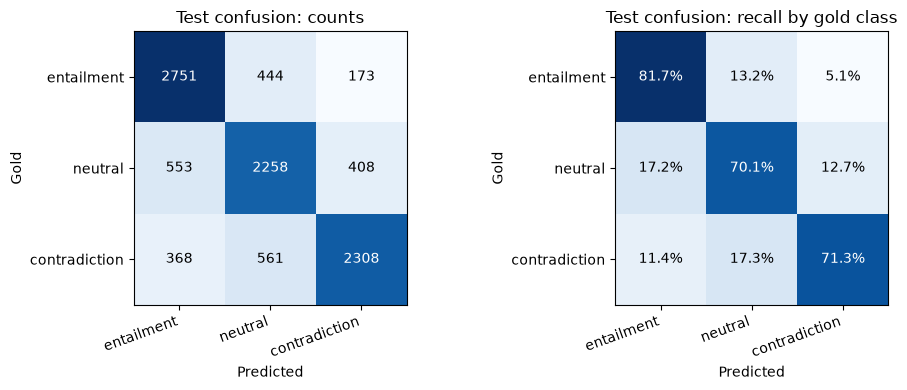

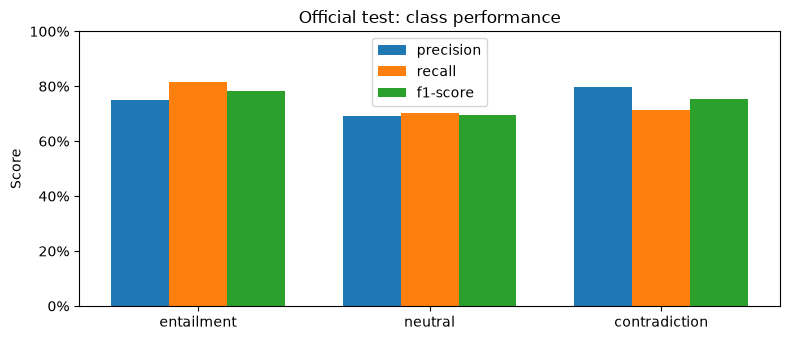

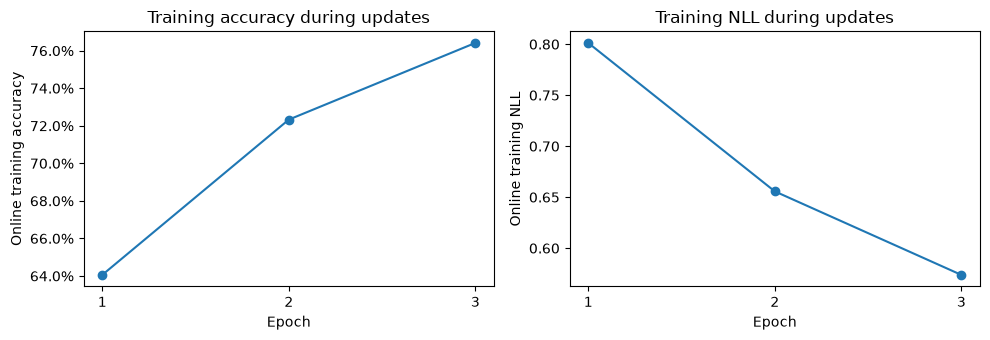

,premise,hypothesis,label,prediction
0,This church choir sings to the masses as they sing joyous songs from the book at a church.,The church has cracks in the ceiling.,neutral,entailment
1,This church choir sings to the masses as they sing joyous songs from the book at a church.,The church is filled with song.,entailment,neutral
2,This church choir sings to the masses as they sing joyous songs from the book at a church.,A choir singing at a baseball game.,contradiction,entailment
3,"A woman with a green headscarf, blue shirt and a very big grin.",The woman is young.,neutral,entailment
4,"A woman with a green headscarf, blue shirt and a very big grin.",The woman is very happy.,entailment,neutral
5,"A woman with a green headscarf, blue shirt and a very big grin.",The woman has been shot.,contradiction,entailment
12,A land rover is being driven across a river.,A Land Rover is splashing water as it crosses a river.,entailment,neutral
14,A land rover is being driven across a river.,A sedan is stuck in the middle of a river.,contradiction,neutral
36,Three firefighter come out of subway station.,Three firefighters putting out a fire inside of a subway station.,neutral,entailment
41,"A person wearing a straw hat, standing outside working a steel apparatus with a pile of coconuts on the ground.",A person is burning a straw hat.,contradiction,neutral


In [48]:
confusion = confusion_matrix(testing.label, test_decisions, labels=[0, 1, 2])
display(pd.DataFrame(confusion, index=LABELS, columns=LABELS))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, values, title in zip(
    axes, [confusion, confusion / confusion.sum(axis=1, keepdims=True)],
    ["Test confusion: counts", "Test confusion: recall by gold class"],
):
    image = ax.imshow(values, cmap="Blues")
    for row in range(3):
        for column in range(3):
            label = str(int(values[row, column])) if title.endswith("counts") else f"{values[row, column]:.1%}"
            ax.text(column, row, label, ha="center", va="center",
                    color="white" if values[row, column] > values.max() / 2 else "black")
    ax.set(xticks=range(3), xticklabels=LABELS, yticks=range(3), yticklabels=LABELS,
           xlabel="Predicted", ylabel="Gold", title=title)
    plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
save_figure(fig, "test_confusion")
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.5))
positions = np.arange(len(LABELS))
for offset, metric in enumerate(["precision", "recall", "f1-score"]):
    ax.bar(positions + (offset - 1) * 0.25, class_report.loc[LABELS, metric],
           width=0.25, label=metric)
ax.set(xticks=positions, xticklabels=LABELS, ylim=(0, 1),
       ylabel="Score", title="Official test: class performance")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
fig.tight_layout()
save_figure(fig, "test_class_metrics")
plt.show()

history = pd.DataFrame(final_model["history"])
if not history.empty:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(history.epoch, history.training_accuracy_online, marker="o")
    axes[0].set(title="Training accuracy during updates", ylabel="Online training accuracy",
                xlabel="Epoch", xticks=history.epoch)
    axes[0].yaxis.set_major_formatter(PercentFormatter(1))
    axes[1].plot(history.epoch, history.training_nll_online, marker="o")
    axes[1].set(title="Training NLL during updates", ylabel="Online training NLL",
                xlabel="Epoch", xticks=history.epoch)
    fig.tight_layout()
    save_figure(fig, "training_curves")
    plt.show()

test_errors = testing.loc[test_decisions != testing.label.to_numpy()].copy()
test_errors["prediction"] = test_decisions[test_decisions != testing.label.to_numpy()]
test_errors["label"] = test_errors.label.map(dict(enumerate(LABELS)))
test_errors["prediction"] = test_errors.prediction.map(dict(enumerate(LABELS)))
with pd.option_context("display.max_colwidth", 140):
    display(test_errors[["premise", "hypothesis", "label", "prediction"]].head(12))


Training curves are online minibatch measurements during updates, with dropout
active. They are not held-out accuracy or a final-model training-pool evaluation.
CV trains on about 48,000 labelled pairs per fold; the final fit uses 559,164.
Their evaluation examples also differ. A CV-to-test score change is not an
isolated estimate of the benefit of more training data.

Vocabulary size changes segmentation, coverage and input dimension, so its
effect can interact with representation and classifier. The size curves keep
those systems fixed. The three per-size winners need not share an architecture.
The selected maximum CV score is subject to selection optimism. Bayesian
comparisons after that selection are descriptive and conditional on this design.
Only one grouped repetition is used, and earlier work already inspected test.


## 9. Tutorial-style result plots

Show boxplots with each of the five fold points at the selected vocabulary size.
Posterior panels compare one factor at a time, with a shaded primary ROPE of
±0.5 pp and 95% credible intervals. Positive differences favour B. Curves use the
Student-t scale consistently with the probability tables; scale is not its SD.

**Model panels (BPE 2,000):** B is **indicators + MLP2** in every panel.
In reading order, A is **indicators + MLP1**, **unigram counts + MLP2**,
**indicators + logistic regression**, then **bigram counts + MLP2**.
Positive B − A differences favour indicator MLP2.

**Vocabulary panels:** keep **indicators + MLP2** fixed across **1,000, 2,000
and 3,000 tokens**. The ROPE sensitivity heatmap includes both model and
vocabulary comparisons and varies only the tolerance.
All comparisons use five held-out CV accuracy scores. These are post-selection
descriptions, not independent confirmation.
All plots are exported as PNG and PDF to `figures/project1_vocab_cv/`.


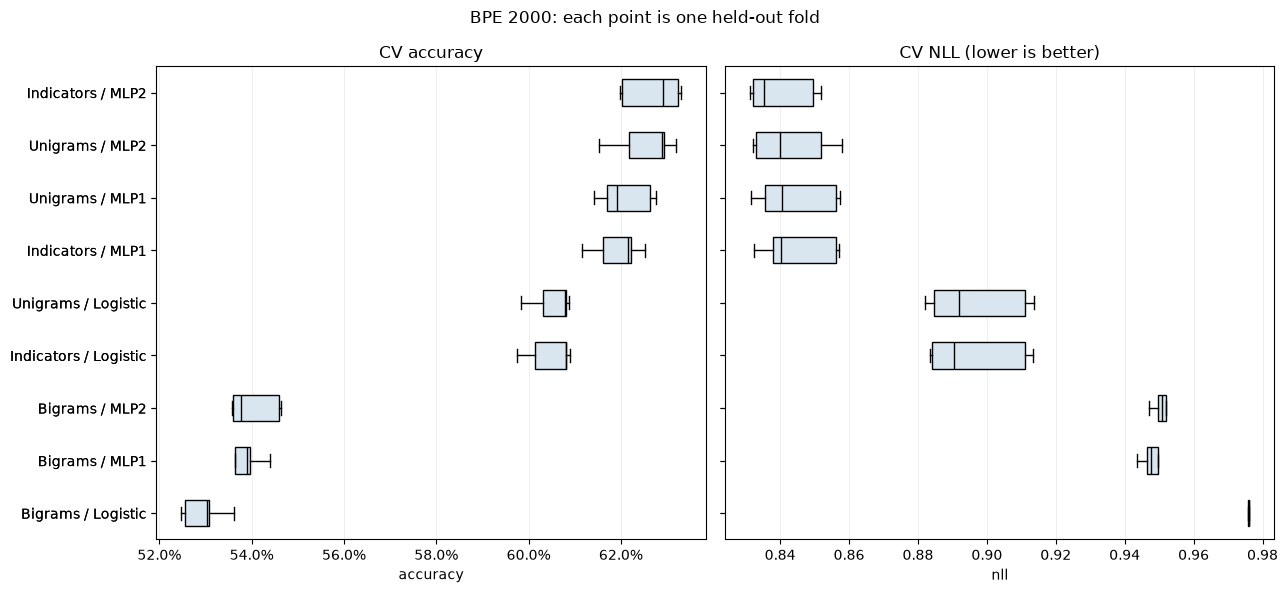

In [49]:
def system_name(system):
    representation, classifier = system
    representations = {"indicators": "Indicators", "unigram_counts": "Unigrams",
                       "bigram_counts": "Bigrams"}
    classifiers = {"logistic": "Logistic", "mlp_one_hidden": "MLP1", "mlp_two_hidden": "MLP2"}
    return f"{representations[representation]} / {classifiers[classifier]}"


systems = list(selected_summary[["representation", "classifier"]].itertuples(index=False, name=None))
labels = [system_name(system) for system in systems]
fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
for ax, metric, title in zip(axes, ["accuracy", "nll"], ["CV accuracy", "CV NLL (lower is better)"]):
    measurements = [selected_results.loc[
        selected_results.representation.eq(representation) & selected_results.classifier.eq(classifier), metric
    ].to_numpy() for representation, classifier in systems]
    ax.boxplot(measurements, orientation="horizontal", tick_labels=labels,
               showfliers=False, patch_artist=True,
               boxprops={"facecolor": "#d9e6ef"}, medianprops={"color": "black"})
    ax.set(title=title, xlabel=metric)
    ax.grid(axis="x", alpha=0.2)
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle(f"BPE {selected_vocab}: each point is one held-out fold")
fig.tight_layout()
save_figure(fig, "cv_boxplots_and_points")
plt.show()


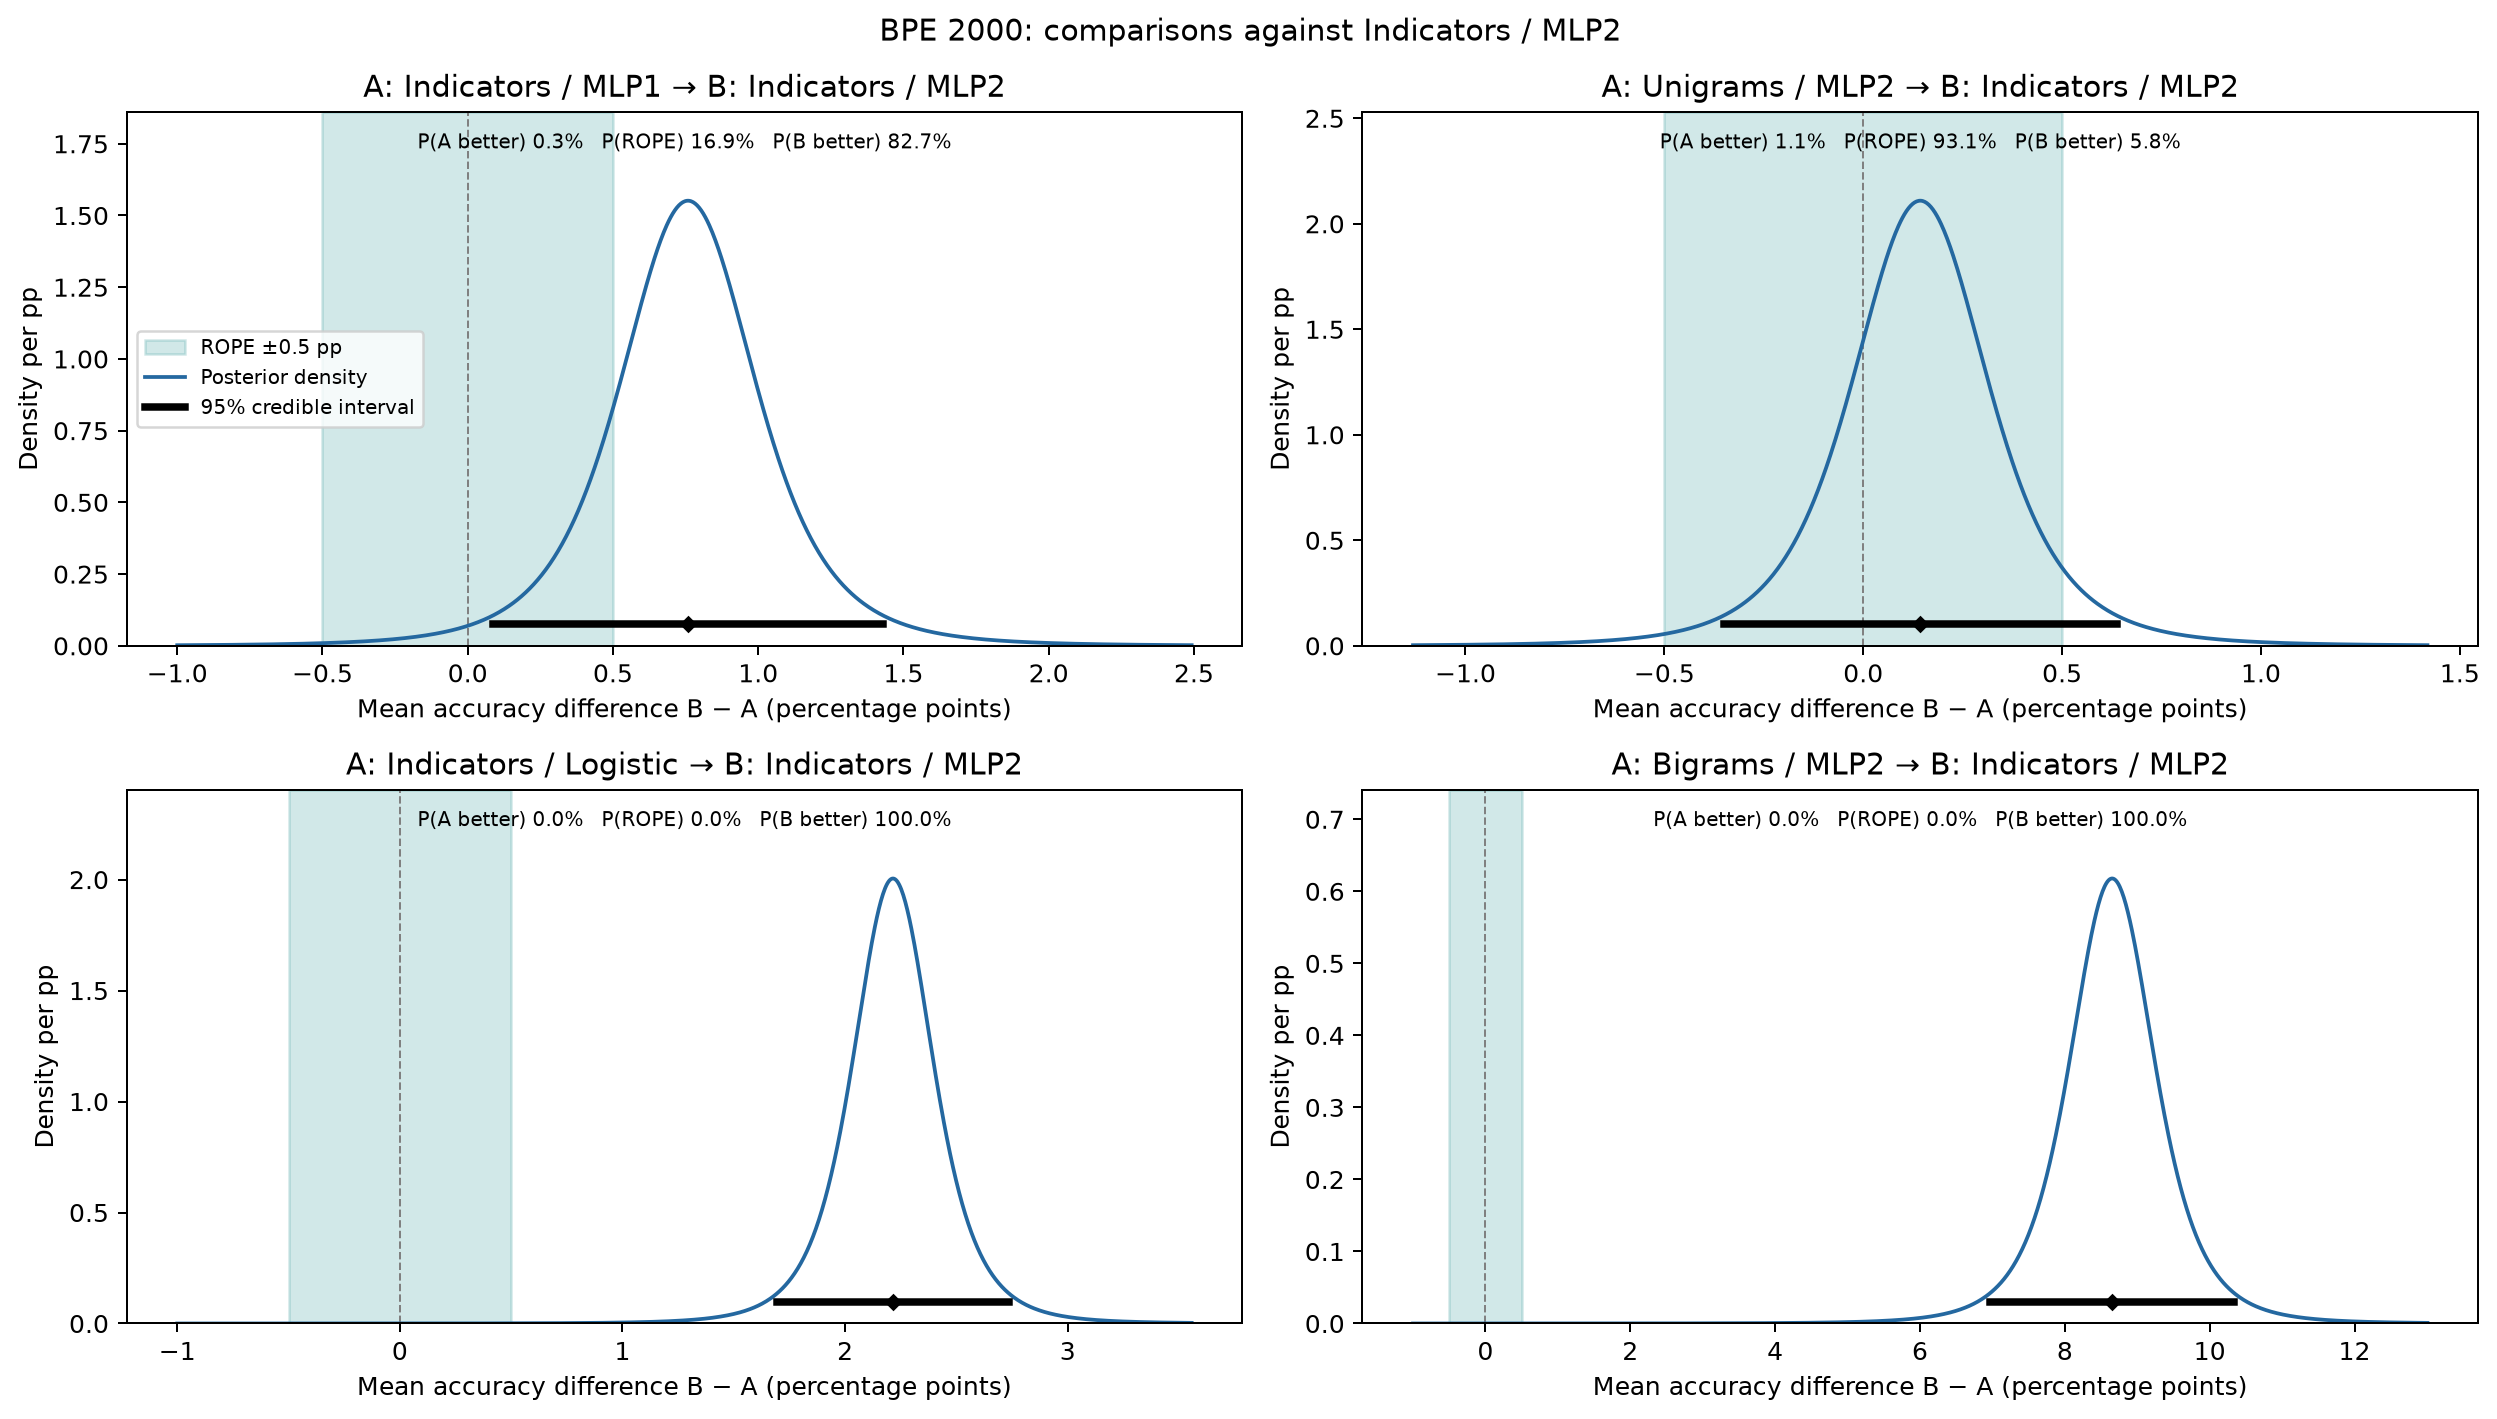

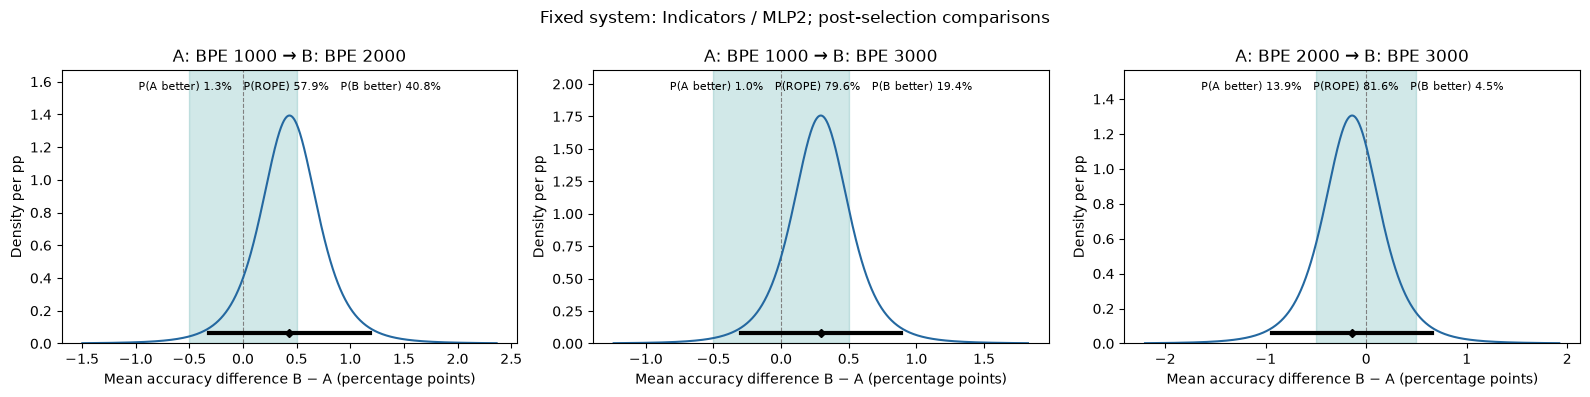

In [50]:
def plot_posterior(ax, scores_a, scores_b, name_a, name_b, config=BASE):
    result = correlated_posterior(scores_a, scores_b, config["n_splits"], config["rope"])
    rope_pp = 100 * config["rope"]
    mean_pp = 100 * result["difference_B_minus_A"]
    scale_pp = 100 * result["student_scale"]
    ax.axvspan(-rope_pp, rope_pp, color="teal", alpha=0.18, label=f"ROPE ±{rope_pp:g} pp")
    ax.axvline(0, color="gray", linewidth=0.8, linestyle="--")
    if scale_pp > 0:
        posterior = t(df=result["degrees_of_freedom"], loc=mean_pp, scale=scale_pp)
        low, high = posterior.interval(0.998)
        x = np.linspace(min(low, -2 * rope_pp), max(high, 2 * rope_pp), 1000)
        ax.plot(x, posterior.pdf(x), color="#2468a0", label="Posterior density")
    else:
        ax.axvline(mean_pp, color="#2468a0", label="Point-mass posterior")
    interval = [100 * result["ci_low"], 100 * result["ci_high"]]
    ax.plot(interval, [0.04, 0.04], transform=ax.get_xaxis_transform(),
            color="black", linewidth=3, label="95% credible interval")
    ax.plot(mean_pp, 0.04, "D", color="black", markersize=4,
            transform=ax.get_xaxis_transform())
    probabilities = (f"P(A better) {result['P_A_better']:.1%}   "
                     f"P(ROPE) {result['P_equivalent']:.1%}   "
                     f"P(B better) {result['P_B_better']:.1%}")
    ax.set(title=f"A: {name_a} → B: {name_b}",
           xlabel="Mean accuracy difference B − A (percentage points)", ylabel="Density per pp")
    ax.text(0.5, 0.96, probabilities, transform=ax.transAxes, ha="center", va="top", fontsize=8)
    ax.margins(y=0.2)
    ax.set_ylim(bottom=0)
    return result


paired_scores = selected_results.pivot(
    index=["seed", "fold"], columns=["representation", "classifier"], values="accuracy"
).sort_index()
plot_contrasts = [
    (("indicators", "mlp_one_hidden"), ("indicators", "mlp_two_hidden")),
    (("unigram_counts", "mlp_two_hidden"), ("indicators", "mlp_two_hidden")),
    (("indicators", "logistic"), ("indicators", "mlp_two_hidden")),
    (("bigram_counts", "mlp_two_hidden"), ("indicators", "mlp_two_hidden")),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (a, b) in zip(axes.flat, plot_contrasts):
    plot_posterior(ax, paired_scores[a], paired_scores[b], system_name(a), system_name(b))
axes[0, 0].legend(fontsize=8, loc="center left")
fig.suptitle(f"BPE {selected_vocab}: comparisons against Indicators / MLP2")
fig.tight_layout()
save_figure(fig, "bayesian_posteriors_rope")
plt.show()


vocab_scores = cv_results.loc[
    cv_results.representation.eq(winner.representation) & cv_results.classifier.eq(winner.classifier)
].pivot(index=["seed", "fold"], columns="vocab_size", values="accuracy").sort_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (a, b) in zip(axes, combinations(BASE["vocab_sizes"], 2)):
    plot_posterior(ax, vocab_scores[a], vocab_scores[b], f"BPE {a}", f"BPE {b}")
fig.suptitle(f"Fixed system: {system_name((winner.representation, winner.classifier))}; post-selection comparisons")
fig.tight_layout()
save_figure(fig, "vocabulary_posteriors")
plt.show()


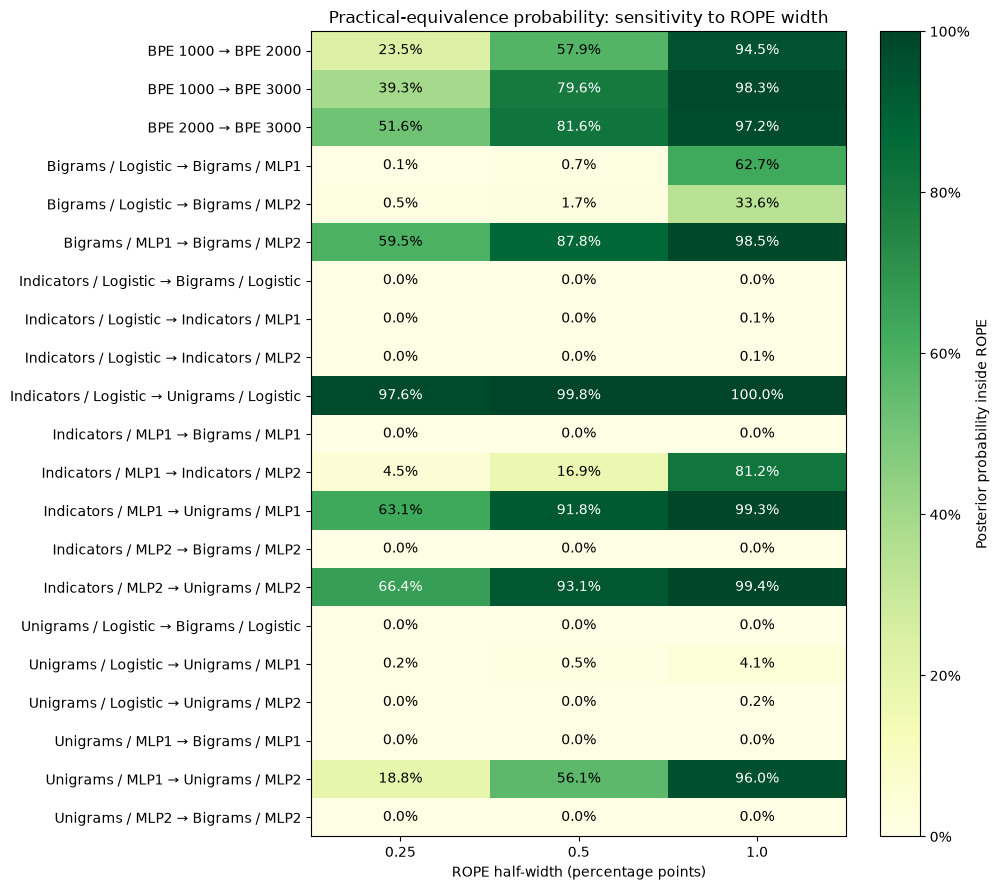

,figure
0,bayesian_posteriors_rope.png
1,cv_accuracy.png
2,cv_boxplots_and_points.png
3,dataset_label_balance.png
4,dataset_sentence_lengths.png
5,rope_sensitivity.png
6,test_class_metrics.png
7,test_confusion.png
8,training_curves.png
9,vocabulary_effect.png


In [51]:
equivalence = sensitivity.pivot(
    index=["A", "B"], columns="ROPE half-width (pp)", values="P_equivalent"
)
comparison_labels = [f"{a} → {b}" if a.startswith("BPE ") else
                     f"{system_name(tuple(a.split(' / ')))} → {system_name(tuple(b.split(' / ')))}"
                     for a, b in equivalence.index]
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(equivalence.to_numpy(), vmin=0, vmax=1, cmap="YlGn", aspect="auto")
for row in range(len(equivalence)):
    for column in range(len(equivalence.columns)):
        value = equivalence.iloc[row, column]
        ax.text(column, row, f"{value:.1%}", ha="center", va="center",
                color="white" if value > 0.65 else "black")
ax.set(xticks=range(len(equivalence.columns)), xticklabels=equivalence.columns,
       yticks=range(len(equivalence)), yticklabels=comparison_labels,
       xlabel="ROPE half-width (percentage points)",
       title="Practical-equivalence probability: sensitivity to ROPE width")
fig.colorbar(image, ax=ax, label="Posterior probability inside ROPE", format=PercentFormatter(1))
fig.tight_layout()
save_figure(fig, "rope_sensitivity")
plt.show()

display(pd.DataFrame({"figure": sorted(path.name for path in FIGURES.glob("*.png"))}))


### Interpreting the vocabulary experiment

The best tested CV system at **1k / 2k / 3k** reaches **62.27% / 62.69% / 62.55%**.
The 1k winner uses unigram counts; the other two use indicators, all with MLP2.
The fixed highest-accuracy rule selects **2k + indicators + MLP2**. The controlled
matrix and curves hold representation/classifier fixed when assessing vocabulary.

For indicator MLP2, moving 1k → 2k changes mean accuracy by **+0.43 pp** and
2k → 3k by **−0.14 pp**. These are small differences: the paired 2k/3k posterior
assigns **81.58%** probability inside the ±0.5 pp ROPE. This is conditional,
post-selection evidence, not proof that 2k is intrinsically optimal. Bigger
vocabularies do not improve every system: all pure-bigram models prefer 1k here.

The cost table also matters: indicator MLP2 has **264,579 / 520,579 / 776,579**
parameters at 1k/2k/3k, while average validation token length falls. The bigram
cap stays 2k throughout; no second hyperparameter was tuned.

CV took **10.09 minutes**; final fresh 2k preprocessing/fitting took **60.25 seconds**.
The final test result is **74.48% accuracy**, NLL **0.6210**, macro-F1 **0.7439**.
This selects the same final recipe as before and reproduces its score. It does
not demonstrate a test-accuracy improvement from vocabulary tuning; the change
is a stricter CV preprocessing boundary and an explicit paired size comparison.
The selected CV maximum is not an unbiased nested-CV estimate. Earlier test use
remains disclosed. Detailed checked results are in
[PROJECT1_FINDINGS.md](PROJECT1_FINDINGS.md).


## Sources and assistance

- [Project requirements](project.ipynb) and [course tutorial](tutorial.ipynb).
- [SNLI dataset](https://huggingface.co/datasets/stanfordnlp/snli), pinned above.
- [Course-method map](COURSE_METHODS.md), with lecture page references.
- Presentation reference: [NLP1 Practical 2](https://github.com/S-Chaudhuri/uva_nlp1_2025/blob/main/NLP1_2025_Practical_2_%28student%29.ipynb).
- [AI-assistance record](AI_ASSISTANCE.md). Implementation and initial interpretation
  were AI-assisted; group members must review, explain and validate the report.
